In [2]:
import shutil
import pandas as pd
import random

import copy
import numpy as np # Import numpy for checking finite values
import matplotlib.pyplot as plt # Import matplotlib for potential debugging

import os
import math # Import math for ceil
from sklearn.manifold import TSNE # Import TSNE to check default perplexity

import os
import glob
import json
import numpy as np
import tensorflow as tf
import sys

In [3]:
import sys
fixed_path = 'C:\\Users\\Enrico Didoli\\0.Master_Thesis\\'
if fixed_path not in sys.path:
    sys.path.append(fixed_path)

old_cellcnn_path = f'{fixed_path}CellCNN/Old_CellCNN/'
if old_cellcnn_path not in sys.path:
    sys.path.append(old_cellcnn_path)

cellcnn_path = f'{fixed_path}CellCNN/'
if cellcnn_path not in sys.path:
    sys.path.append(cellcnn_path)
    
general_functions_path = f'{fixed_path}General_Functions/'
if general_functions_path not in sys.path:
    sys.path.append(general_functions_path)


In [4]:
decache_files = ['timepoints_elaboration', 'results_elaboration', 'new_datasets_generation', 'run_models',
                 'old_cellCnn.model', 'old_cellCnn.utils', 'old_cellCnn.downsample', 'old_cellCnn.model_grid' ]

# Rimuovi il modulo specifico dalla cache
from timepoints_elaboration import remove_from_cache
remove_from_cache(decache_files)


# import downloaded modules
from old_cellCnn.model import CellCnn

import old_cellCnn.utils as utils
import old_cellCnn.downsample as downsample

from timepoints_elaboration import load_data, donation_extraction, dataset_elaboration
from timepoints_elaboration import donor_division, patient_code_extraction, remove_from_cache

from results_elaboration import extract_hyper, phenotype_prediction, default_serializer, show_hyperparameters
from results_elaboration import elaborate_predictions, show_hyper

from run_models import trials_train_CellCNN, trials_test_CellCNN, trials_train_CellCNN_old, trials_test_CellCNN_old

from new_datasets_generation import splitting_and_dataset_elaboration

timepoints_elaboration rimosso dalla cache
results_elaboration non trovato nella cache
new_datasets_generation non trovato nella cache
run_models non trovato nella cache
old_cellCnn.model non trovato nella cache
old_cellCnn.utils non trovato nella cache
old_cellCnn.downsample non trovato nella cache
old_cellCnn.model_grid non trovato nella cache


In [5]:
import sys
import numpy as np
import pandas as pd

def get_actual_size(obj):
    """Get TRUE memory size"""
    if isinstance(obj, pd.DataFrame):
        return obj.memory_usage(deep=True).sum()
    elif isinstance(obj, pd.Series):
        return obj.memory_usage(deep=True)
    elif isinstance(obj, np.ndarray):
        return obj.nbytes
    elif isinstance(obj, (list, tuple, set, dict)):
        # For containers, sum up contents
        return sys.getsizeof(obj) + sum(sys.getsizeof(item) for item in obj)
    else:
        return sys.getsizeof(obj)

def print_var_memory(var_to_check = None):
    # Display all variables with ACTUAL sizes
    all_vars = %who_ls
    sizes = []
    if var_to_check is None:
        var_to_check = all_vars

    
    for var_name in all_vars:
        #try:
            var = eval(var_name)
           
            #if var_name in  ('train_datasets_extracted','val_datasets_extracted','test_datasets_extracted'):
            if var_name in var_to_check:
                #print(var)
                if isinstance(var, (list, tuple)):
                    var = flatten(var)
                    tot = 0
                    for element in var:
                        tot += get_actual_size(element)
                    size = tot
                    sizes.append((var_name, type(var).__name__, size))
            else:
                size = get_actual_size(var)
                sizes.append((var_name, type(var).__name__, size))
        
        #except:
        #    pass
    
    # Sort by size
    sizes.sort(key=lambda x: x[2], reverse=True)
    
    # Pretty print
    print(f"{'Variable':<25} {'Type':<20} {'Memory':>15}")
    print("-" * 65)
    total = 0
    var_to_check = []
    for name, type_name, size in sizes:
        total += size
        if size > 1024**3:  # GB
            print(f"{name:<25} {type_name:<20} {size/(1024**3):>12.2f} GB")
            var_to_check.append(name)
            
        elif size > 1024**2:  # MB
            print(f"{name:<25} {type_name:<20} {size/(1024**2):>12.2f} MB")
            var_to_check.append(name)
        '''
        elif size > 1024:  # KB
            print(f"{name:<25} {type_name:<20} {size/1024:>12.2f} KB")
        
        else:
            print(f"{name:<25} {type_name:<20} {size:>12} bytes")
        '''
    print("-" * 65)
    print(f"{'TOTAL':<25} {'':<20} {total/(1024**3):>12.2f} GB")
    return var_to_check
    


In [6]:
def remove_labels(new_test_datasets):
    new_no_label_test_datasets = []
    for dataset in new_test_datasets:
        if 'IsBlast' in dataset.columns:
            dataset = dataset.drop(columns = ['IsBlast'])
        
        new_no_label_test_datasets.append(dataset)
    print(len(new_no_label_test_datasets))
    return new_no_label_test_datasets

def show_blast_distribution(ALL_DATASETS, return_perc = False):
    tot_perc_list = []
    for i, dataset in enumerate(ALL_DATASETS):
        blast_n = (dataset['IsBlast'] == 1).sum()
        tot_perc_list.append(round((blast_n/len(dataset))*100, 2))
    
    positions = range(1, len(tot_perc_list) + 1)
    
    fig, ax1 = plt.subplots(figsize = [len(positions)/2,4])
    ax1.bar(list(range(1, len(tot_perc_list) + 1)), [max(tot_perc_list)]*len(tot_perc_list), alpha = 0.5)
    ax1.bar(list(range(1, len(tot_perc_list) + 1)), tot_perc_list)
    ax1.set_xticks(positions)
    
    ax2 = ax1.twiny()
    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]
    
    ax2.set_xticklabels(tot_perc_list, size = 'x-small')
    plt.show()

    if return_perc:
        return tot_perc_list

def grid_or_rand_model(grid):
    if grid:
        remove_from_cache(['old_cellCnn.model_grid'])
        from old_cellCnn.model_grid import CellCnn
    else:
        remove_from_cache(['old_cellCnn.model'])
        from old_cellCnn.model import CellCnn
    return CellCnn

def train_val_finalizing(train_datasets, val_datasets, grid, labels):
    
    if grid:
        train = remove_labels(train_datasets)
        val = remove_labels(val_datasets)
        print(f'_abels from Train and Validations Sets have been REMOVED.\nGrid Search Ready!')
    else:
        if not labels: # if random search but we don't want use labels
            train = remove_labels(train_datasets)
            val = remove_labels(val_datasets)
            print(f'labels from Train and Validations Sets have been REMOVED.\nRandom Search Ready!')
            
        else:
            train = train_datasets
            val = val_datasets
            print(f'Labels from Train and Validations Sets have been PRESERVED.\nRandom Search Ready!')
            
    return train, val

def prepare_results_to_save(results_list, par_list = ['config', 'model_sorted_idx']):
    tot_trials_res = []

    for res in results_list:
        needed_results = {}
        for key, value in res.items():
            if key in par_list:
                needed_results[key] = value
                
        tot_trials_res.append(needed_results)
    return tot_trials_res

def retrieve_labels(datasets_extracted, remove = False, concat = False):
    
    per_donor_original_datasets = []
    per_donor_original_y = []

    for donor in datasets_extracted:
        donor_datasets = []
        donor_ys = []
        for dataset in donor:
            if (dataset['IsBlast'] == 1).sum() > 0:
                donor_ys.append(1)
            else:
                donor_ys.append(0)
                
            if remove:
                dataset = dataset.drop(columns = ['IsBlast'])

            donor_datasets.append(dataset)

        if concat:
            per_donor_original_datasets += donor_datasets
            per_donor_original_y += donor_ys
        else:
            per_donor_original_datasets.append(donor_datasets)
            per_donor_original_y.append(donor_ys)
            
    return per_donor_original_datasets, per_donor_original_y 

def subset_sampling(dataset, ncells, nsubsets, seed):
    resampled_datasets = []
    resampled_y = []
    blast_perc = []
    
    for i in range(nsubsets):
        seed += 10
        #print(f'seed:{seed}')
        resampled_cells = dataset.sample(ncells, replace = True, random_state = seed).reset_index(drop=True) # sample cells
            
        if (resampled_cells['IsBlast'] == 1).sum() > 0: #check label
                resampled_y.append(1)
                blast_perc.append((resampled_cells[resampled_cells['IsBlast'] == 1]).sum()/len(resampled_cells))
        else:
                resampled_y .append(0)
                blast_perc.append(0)
        resampled_cells = resampled_cells.drop(columns = ['IsBlast']) #remove isblast column

        resampled_datasets.append(resampled_cells) 
    return    resampled_datasets,  resampled_y , blast_perc, seed


def get_timepoints_predictions(total_pred_lists, per_donor_original_test_y, threshold):
    total_labels = []
    
    for patient in total_pred_lists:
        patient_timepoints_labels = []
        
        for timepoint in patient:
            timepoint_f1_scores = []
            blast_labelled_timepoint_scores = []
            
            true_y = timepoint.iloc[-1]
            
            for trial in range(len(timepoint.iloc[:-1])): # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                sub = timepoint.iloc[trial]               # each sub is a pediction of the 20 samples of a single timepoint
                blast_labelled_perc = sub.sum()/len(true_y)
                blast_labelled_timepoint_scores.append(blast_labelled_perc) #percentage of timepoints labelled as with blast cells
     
            mean_timepoint_blast_score = np.mean(blast_labelled_timepoint_scores) # mean percentage of timepoints labelled as with blast cells
            
            if mean_timepoint_blast_score >= threshold*0.01:
                patient_timepoints_labels.append(1)
            else:
                patient_timepoints_labels.append(0)
                
        total_labels.append(patient_timepoints_labels)
    return total_labels


def get_trial_pred_per_timepoint(total_pred_lists, per_donor_original_test_y):
    plot_data = []
    boxplot_data = []
    total_timepoint_prediction_per_trial = []
    
    for patient, patient_ys in zip(total_pred_lists, per_donor_original_test_y):
        timepoint_prediction_per_trial = []
        
        for timepoint, true_timepoint_y in zip(patient, patient_ys):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"
            
            trial_level_label_prediction = []
            true_y = timepoint.iloc[-1]
            timepoint_boxplot_data = []
            
            for trial in range(len(timepoint.iloc[:-1])): # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                sub = timepoint.iloc[trial]               # each sub is a pediction of the 20 samples of a single timepoint
                
                trial_perc = sub.sum()/len(true_y)
                #trial_perc = sub.sum()/min(1, true_y.sum())
            
                #trial_level_label_prediction.append((blast_labelled_perc >= threshold*0.01).astype(int))
                plot_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_perc
                })
                
                timepoint_boxplot_data.append(trial_perc)
                
            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })
                
    return plot_data, boxplot_data

def compute_timepoint_best_f1(timepoint_preds):
        """we are taking the best f1 score. because we are not tuning the model. we are just trying to predict the label of the timepoint"""
        timepoint_score = []
        
        resampled_true_y = timepoint_preds.iloc[-1] # get labels of resampled subsets
        #print(timepoint_preds.iloc[:-1]) #labels

        # initialize variables
        best_f1 = -1
        counter = 0
        
        for h in range(len(timepoint_preds) - 1):
            sub = timepoint_preds.iloc[h] # extrsct trial pediction
            
            f1 = f1_score(resampled_true_y, sub, pos_label = 1) # compute the f1_score
            if f1 > best_f1:
                best_f1_idx = counter
            counter += 1
            
        print(best_f1_idx)   
        best_sub = timepoint_preds.iloc[best_f1_idx]
        #print(len(true_y))
        blast_score = best_sub.sum() 
        print('')
        #print(best_sub)
        #print(f'blast_score: {blast_score}\n')
        timepoint_score = blast_score.sum()/len(resampled_true_y)
        return (timepoint_score, list(resampled_true_y))


def find_threshold(total_scores, per_donor_original_val_y):
    best_f1 = -1
    best_thr = -1
    tot_mean_f1_scores = []
    threshold_predictions = []
    for threshold in list(range(1,101)):
        f1_scores = []
        patient_predictions = []
        for patient_score, patient_y in zip(total_scores, per_donor_original_val_y):
            scores = []
            
            for timep in patient_score:
                # get mean columns predicted probabilities 
                scores.append(timep[0]) 
            
            y_pred = []
            y_pred = (np.array(scores) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
            #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')
            #print(patient_y)
            #print(y_pred)
            timepoint_f1_score = f1_score(patient_y, y_pred, pos_label = 1, zero_division=1)
            #print(f'f1_score: {timepoint_f1_score}\n')
        
            f1_scores.append(timepoint_f1_score)
            
            patient_predictions.append(list(y_pred))
            
        threshold_predictions.append(patient_predictions)
    
        #print(f1_scores)
        mean_f1_score = np.mean(f1_scores)
        tot_mean_f1_scores.append(mean_f1_score)
        
        if mean_f1_score > best_f1:
                best_f1 = mean_f1_score
                best_thr = threshold*0.01
        #print('')
    
        #patient_f1_scores.append(timepoint_f1_score)
    #plot thresholds
    plt.plot(list(range(1,101)), tot_mean_f1_scores)
    #for th in threshold_predictions:
        #print(th)

    #find threshold
    max_mean_f1 = max(tot_mean_f1_scores)
    best_thresholds_idx = []
    
    best_thresholds_idx = [i for i, f1 in enumerate(tot_mean_f1_scores) if f1 == max_mean_f1]
    #print(best_thresholds_idx)
    
    robust_best_thr_idx = np.median(best_thresholds_idx)
    #print(np.median(list(range(5))))
    print(f'Chosen threshold: {robust_best_thr_idx}' )
    return robust_best_thr_idx


def flatten(nested):
    if nested is None:
        return []
    if not isinstance(nested, (list, tuple)):
        return [nested]
    nested = list(nested)
    result = []
    for item in nested:
        result.extend(flatten(item))
    return result

In [7]:
import json
config_path = f'{fixed_path}CellCNN\\results\\old\\'
with open(f'{config_path}configuration_positive_highest_first.json', 'r', encoding="utf-8") as f:
    config = json.load(f)
print(config)

seed = config['seed']
n_sub = config['n_sub']
n_cells = config['n_cells']
blast_perc = config['blast_perc']
best_nsub = config['best_nsub']

print(seed)
print(n_sub)
print(n_cells)
print(blast_perc)
print(best_nsub)

{'seed': 42, 'n_sub': 3, 'n_cells': 100000, 'blast_perc': [0.001, 0.005, 0.01], 'best_nsub': 780, 'sorted_nsubs_list': [640, 740, 760, 780, 800], 'acc_5_to_plot': [0.6933333333333334, 0.76, 0.7866666666666667, 0.8800000000000001, 0.76], 'f1_5_to_plot': [0.3238095238095238, 0.5342857142857143, 0.5751515151515151, 0.8054545454545454, 0.5504761904761905]}
42
3
100000
[0.001, 0.005, 0.01]
780


In [8]:
%%time

# Trova tutti i file con estensione specifica in una cartella
data_folder = f'{fixed_path}B-ALL_Datasets'
extension = '*.csv'  # cambia con l'estensione che ti serve

multiple_donations, ALL_DATASETS = load_data(data_path = data_folder, ext = extension)

Elaborating file 0: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220204-2900.csv
Elaborating file 1: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220208-3665.csv
Elaborating file 2: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_220216-3546.csv
Elaborating file 3: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D15_1.csv
Elaborating file 4: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D29_1.csv
Elaborating file 5: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE11_D71_1.csv
Elaborating file 6: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D15_2.csv
Elaborating file 7: C:\Users\Enrico Didoli\0.Master_Thesis\B-ALL_Datasets\B-ALL_expression_matrix_B-ALL_GHE12_D29_1.csv
Elaborating file 8: C:\Users\Enrico Didoli\0.Master_Thesis

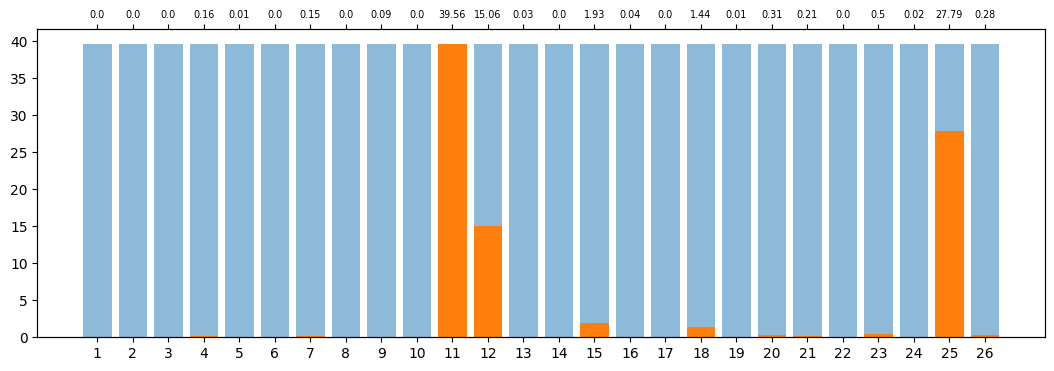

In [9]:

show_blast_distribution(ALL_DATASETS, return_perc = False)

In [10]:
healthy_donors, blast_donors, mixed_donors = donor_division(multiple_donations, ALL_DATASETS)

print(healthy_donors, blast_donors, mixed_donors)

{'11': [1, 1, 0], '12': [1, 1], '1': [1, 0], '2': [1, 1], '3': [1, 0], '4': [1, 1, 0], '6': [1, 1], '7': [1, 1, 0], '8': [1, 1], '9': [1, 1], '13': [0], '14': [0], '15': [0]}
['13', '14', '15'] ['12', '2', '6', '8', '9'] ['11', '1', '3', '4', '7']


In [11]:

# Samples donors for Train, Validation and Test sets    
seed = 105619

train_donors_idx, val_donors_idx, test_donors_idx = dataset_elaboration(multiple_donations, ALL_DATASETS, healthy_donors, blast_donors,
                        mixed_donors, seed = seed)

mod = 3
ncell_path = f'{fixed_path}CellCNN\\results\\old\\ncells_tuning\\'
with open(f'{ncell_path}folder_testing\\model_{mod}\\best_fold_{mod}.json', 'r', encoding="utf-8") as f:
     train_donors_idx, val_donors_idx = json.load(f)
print(train_donors_idx, val_donors_idx, test_donors_idx)

Precess starts. Dividing donors...
healthy_donors_idx, blast_donors_idx, mixed_donors_idx: [0, 2, 1], [0, 4, 2, 1, 3],[4, 0, 2, 1, 3]
Seting Train, Validation and Test idx...
['12', '9', '13', '7'] ['6', '15', '3'] ['2', '8', '14', '11', '1', '4']
['3', '15', '6', '7', '9'] ['13', '12'] ['2', '8', '14', '11', '1', '4']


In [12]:
'''
h_pat = healthy_donors.copy()
m_pat = mixed_donors.copy()
b_pat = blast_donors.copy()
for patient in test_donors_idx:
    if patient in healthy_donors:
        h_pat.remove(patient)
    elif patient in mixed_donors:
        m_pat.remove(patient)
    elif patient in blast_donors:
        b_pat.remove(patient)

print(f'Available healthy patients fof CV: {h_pat}')
print(f'Available mixed patients fof CV: {m_pat}')
print(f'Available blast patients fof CV: {b_pat}')

#for pat in h_pat:
#    for file in
'''

"\nh_pat = healthy_donors.copy()\nm_pat = mixed_donors.copy()\nb_pat = blast_donors.copy()\nfor patient in test_donors_idx:\n    if patient in healthy_donors:\n        h_pat.remove(patient)\n    elif patient in mixed_donors:\n        m_pat.remove(patient)\n    elif patient in blast_donors:\n        b_pat.remove(patient)\n\nprint(f'Available healthy patients fof CV: {h_pat}')\nprint(f'Available mixed patients fof CV: {m_pat}')\nprint(f'Available blast patients fof CV: {b_pat}')\n\n#for pat in h_pat:\n#    for file in\n"

In [13]:

#  Retrieves specific donor datasets from all datasets list
train_datasets_extracted = donation_extraction(train_donors_idx, multiple_donations, ALL_DATASETS)
val_datasets_extracted = donation_extraction(val_donors_idx, multiple_donations, ALL_DATASETS)
test_datasets_extracted = donation_extraction(test_donors_idx, multiple_donations, ALL_DATASETS)


print(len(train_datasets_extracted)) # list of donators
print(len(train_datasets_extracted[0])) # list of donations
print(len(test_datasets_extracted[0][0])) # dataset of cells

5
2
778750


In [14]:
'''
#n_sub = 3
#seed = 42
#n_cells = 100000
#blast_perc = [0.001, 0.005, 0.01]

new_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y = splitting_and_dataset_elaboration(train_datasets_extracted, 
                                                                                    val_datasets_extracted, test_datasets_extracted,
                                                                                    n_sub, n_cells, seed, blast_perc = blast_perc, per_perc = True)

#show_blast_distribution(new_test_datasets)
print(len(new_val_datasets))
print(len(new_test_datasets))
print(len(new_val_y))
'''

'\n#n_sub = 3\n#seed = 42\n#n_cells = 100000\n#blast_perc = [0.001, 0.005, 0.01]\n\nnew_train_datasets, new_train_y, new_val_datasets, new_val_y, new_test_datasets, new_test_y = splitting_and_dataset_elaboration(train_datasets_extracted, \n                                                                                    val_datasets_extracted, test_datasets_extracted,\n                                                                                    n_sub, n_cells, seed, blast_perc = blast_perc, per_perc = True)\n\n#show_blast_distribution(new_test_datasets)\nprint(len(new_val_datasets))\nprint(len(new_test_datasets))\nprint(len(new_val_y))\n'

In [15]:
original_train_datasets, original_train_y = retrieve_labels(train_datasets_extracted, remove = True, concat = True)
print(len(original_train_datasets))
print(original_train_y)

original_val_datasets, original_val_y = retrieve_labels(val_datasets_extracted, remove = True, concat = True)
print(len(original_val_datasets))
print(original_val_y)

original_test_datasets, original_test_y = retrieve_labels(test_datasets_extracted, remove = True, concat = True)
print(len(original_test_datasets))
print(original_test_y)


10
[1, 0, 0, 1, 1, 1, 1, 0, 1, 1]
3
[0, 1, 1]
13
[1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0]


In [16]:
%%time
seed_list = [7359, 9654, 4557, 106, 2615, 6924, 5574, 4552, 2547, 3527]

nfilter = [3, 5, 7, 9] #list(range(3, 10))
print(nfilter)
maxpool_p = [0.01, 1., 5., 20., 100.]
learning_r = [0.001] #, 0.005]
hyper = (nfilter, maxpool_p, learning_r)



[3, 5, 7, 9]
CPU times: total: 0 ns
Wall time: 0 ns


In [17]:
%%time
predictions_list, results_list = [], []
original_predictions_list = []

grid = True  #grid search
labels = False # the  subsets sampled by the model do not maintain original blast distribution
CellCnn = grid_or_rand_model(grid) # loads the correct model module

train, val = train_val_finalizing(original_train_datasets, original_val_datasets, grid, labels)
test = remove_labels(original_test_datasets)
no_label_val = remove_labels(original_val_datasets)

del original_train_datasets
del original_val_datasets
del original_test_datasets
del ALL_DATASETS



old_cellCnn.model_grid non trovato nella cache
10
3
_abels from Train and Validations Sets have been REMOVED.
Grid Search Ready!
13
3
CPU times: total: 125 ms
Wall time: 365 ms


In [18]:
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
test_datasets_extracted   list                         1.13 GB
test                      list                         1.03 GB
train_datasets_extracted  list                       419.72 MB
train                     list                       384.75 MB
val_datasets_extracted    list                       353.01 MB
no_label_val              list                       323.59 MB
val                       list                       323.59 MB
-----------------------------------------------------------------
TOTAL                                                  3.92 GB


['test_datasets_extracted',
 'test',
 'train_datasets_extracted',
 'train',
 'val_datasets_extracted',
 'no_label_val',
 'val']

In [19]:


trials = 10
cells_per_sub = 200
models_lists = trials_train_CellCNN_old(CellCnn, train, #new_train_datasets_no_labels, 
                              original_train_y, 
                              val, #new_val_datasets_no_labels, 
                              original_val_y, test, trials = trials,
                              n_cell = cells_per_sub, nsubset = 1000, #best_nsub,
                              max_epochs=50, nrun=15, seed_list = seed_list, hyper = hyper)



Trial 1 started
Seed used: 7359
Model defined...
Fitting started...
10
10
[1 0 0 1 1 1 1 0 1 1]
11
11
200
200
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 7359
Adopted Parameters: (3, 0.01, 0.001)
200
200
Epoch 1/50
50/50 [==============================] - 4s 16ms/step - loss: 0.6700 - f1_score: 0.4429 - val_loss: 0.6516 - val_f1_score: 0.4000
Epoch 2/50
50/50 [==============================] - 0s 5ms/step - loss: 0.6277 - f1_score: 0.4118 - val_loss: 0.6268 - val_f1_score: 0.4000
Epoch 3/50
50/50 [==============================] - 0s 6ms/step - loss: 0.6105 - f1_score: 0.4502 - val_loss: 0.5980 - val_f1_s

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Trial 2 started
Seed used: 19308
Model defined...
Fitting started...
10
10
[1 0 0 1 1 1 1 0 1 1]
11
11
200
200
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 19308
Adopted Parameters: (3, 0.01, 0.001)
200
200
Epoch 1/50
50/50 [==============================] - 1s 10ms/step - loss: 0.6693 - f1_score: 0.4394 - val_loss: 0.6518 - val_f1_score: 0.4000
Epoch 2/50
50/50 [==============================] - 0s 5ms/step - loss: 0.6279 - f1_score: 0.4118 - val_loss: 0.6294 - val_f1_score: 0.4000
Epoch 3/50
50/50 [==============================] - 0s 6ms/step - loss: 0.6101 - f1_score: 0.4518 - val_loss: 0.6023 - val_f1

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Trial 3 started
Seed used: 13671
Model defined...
Fitting started...
10
10
[1 0 0 1 1 1 1 0 1 1]
11
11
200
200
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 13671
Adopted Parameters: (3, 0.01, 0.001)
200
200
Epoch 1/50
50/50 [==============================] - 1s 9ms/step - loss: 0.6704 - f1_score: 0.4399 - val_loss: 0.6522 - val_f1_score: 0.4000
Epoch 2/50
50/50 [==============================] - 0s 5ms/step - loss: 0.6294 - f1_score: 0.4118 - val_loss: 0.6272 - val_f1_score: 0.4000
Epoch 3/50
50/50 [==============================] - 0s 5ms/step - loss: 0.6104 - f1_score: 0.4520 - val_loss: 0.5981 - val_f1_

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


... (10 outputs left out)

Trial 9 started
Seed used: 22923
Model defined...
Fitting started...
10
10
[1 0 0 1 1 1 1 0 1 1]
11
11
200
200
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 22923
Adopted Parameters: (3, 0.01, 0.001)
200
200
Epoch 1/50
50/50 [==============================] - 1s 9ms/step - loss: 0.6685 - f1_score: 0.4397 - val_loss: 0.6339 - val_f1_score: 0.4000
Epoch 2/50
50/50 [==============================] - 0s 5ms/step - loss: 0.6105 - f1_score: 0.4118 - val_loss: 0.5787 - val_f1_score: 0.4000
Epoch 3/50
50/50 [==============================] - 0s 5ms/step - loss: 0.5752 - f1_score: 0.4577 - val_loss: 0.5244 - val_f1_

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Trial 10 started
Seed used: 35270
Model defined...
Fitting started...
10
10
[1 0 0 1 1 1 1 0 1 1]
11
11
200
200
(3, 0.01, 0.001)
(3, 1.0, 0.001)
(3, 5.0, 0.001)
(3, 20.0, 0.001)
(3, 100.0, 0.001)
(5, 0.01, 0.001)
(5, 1.0, 0.001)
(5, 5.0, 0.001)
(5, 20.0, 0.001)
(5, 100.0, 0.001)
(7, 0.01, 0.001)
(7, 1.0, 0.001)
(7, 5.0, 0.001)
(7, 20.0, 0.001)
(7, 100.0, 0.001)
(9, 0.01, 0.001)
(9, 1.0, 0.001)
(9, 5.0, 0.001)
(9, 20.0, 0.001)
(9, 100.0, 0.001)
Total number of selections: 20

# ============================================= #
Run: 0

Seed: 35270
Adopted Parameters: (3, 0.01, 0.001)
200
200
Epoch 1/50
50/50 [==============================] - 1s 9ms/step - loss: 0.6690 - f1_score: 0.4375 - val_loss: 0.6348 - val_f1_score: 0.4000
Epoch 2/50
50/50 [==============================] - 0s 5ms/step - loss: 0.6136 - f1_score: 0.4118 - val_loss: 0.5817 - val_f1_score: 0.4000
Epoch 3/50
50/50 [==============================] - 0s 5ms/step - loss: 0.5788 - f1_score: 0.4522 - val_loss: 0.5259 - val_f1

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [20]:
print_var_memory()

Variable                  Type                          Memory
-----------------------------------------------------------------
test_datasets_extracted   list                         1.13 GB
test                      list                         1.03 GB
train_datasets_extracted  list                       419.72 MB
train                     list                       384.75 MB
val_datasets_extracted    list                       353.01 MB
no_label_val              list                       323.59 MB
val                       list                       323.59 MB
-----------------------------------------------------------------
TOTAL                                                  3.92 GB


['test_datasets_extracted',
 'test',
 'train_datasets_extracted',
 'train',
 'val_datasets_extracted',
 'no_label_val',
 'val']

## Predicts timepoints directly

In [21]:
original_train_datasets, original_train_y = retrieve_labels(train_datasets_extracted, remove = True, concat = True)
print(len(original_train_datasets))
print(original_train_y)

original_val_datasets, original_val_y = retrieve_labels(val_datasets_extracted, remove = True, concat = True)
print(len(original_val_datasets))
print(original_val_y)

original_test_datasets, original_test_y = retrieve_labels(test_datasets_extracted, remove = True, concat = True)
print(len(original_test_datasets))
print(original_test_y)

del test
del val
del train

10
[1, 0, 0, 1, 1, 1, 1, 0, 1, 1]
3
[0, 1, 1]
13
[1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0]


In [22]:
%%time
original_predictions_list, original_results_list = trials_test_CellCNN_old(models_lists, original_test_datasets)

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 134ms/step
Done
Trial 1 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 200ms/step
Done
Trial 2 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (11 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 129ms/step
Done
Trial 9 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

1/1 [==============================] - 0s 154ms/step
Done
Trial 10 Done!

CPU times: total: 1min 28s
Wall time: 1min 18s


In [23]:
original_pred_phenotype_df, original_accuracy_list, original_f1_score_list = elaborate_predictions(original_predictions_list, original_test_y, results = True)

Trial 0 Accuracy: 0.7692307692307693
Trial 0 F1_score: 0.8421052631578947
Trial 1 Accuracy: 0.7692307692307693
Trial 1 F1_score: 0.8235294117647058
Trial 2 Accuracy: 0.9230769230769231
Trial 2 F1_score: 0.9473684210526315
Trial 3 Accuracy: 0.8461538461538461
Trial 3 F1_score: 0.8888888888888888
Trial 4 Accuracy: 0.8461538461538461
Trial 4 F1_score: 0.8888888888888888
Trial 5 Accuracy: 0.8461538461538461
Trial 5 F1_score: 0.8888888888888888
Trial 6 Accuracy: 0.8461538461538461
Trial 6 F1_score: 0.8888888888888888
Trial 7 Accuracy: 0.7692307692307693
Trial 7 F1_score: 0.8571428571428571
Trial 8 Accuracy: 0.7692307692307693
Trial 8 F1_score: 0.8421052631578947
Trial 9 Accuracy: 0.8461538461538461
Trial 9 F1_score: 0.8888888888888888
             0   1   2   3   4   5   6   7   8   9   10  11  12
0             0   1   1   1   1   1   1   0   1   0   1   1   1
1             0   1   1   0   1   1   1   0   1   0   1   1   0
2             1   1   1   1   1   1   1   0   1   0   1   1   0
3   

In [24]:

tot_trials_res = prepare_results_to_save(results_list)

In [25]:
per_donor_original_test_datasets, per_donor_original_test_y = retrieve_labels(test_datasets_extracted, remove = False, concat = False)
print(len(per_donor_original_test_datasets))
print(per_donor_original_test_y)

6
[[1, 1], [1, 1], [0], [1, 1, 0], [1, 0], [1, 1, 0]]


In [26]:
print(original_predictions_list)

[array([[6.66149616e-01, 3.33850394e-01],
       [3.09393377e-03, 9.96906082e-01],
       [4.15014160e-04, 9.99584953e-01],
       [3.17044643e-01, 6.82955340e-01],
       [2.42449567e-01, 7.57550418e-01],
       [4.67475108e-04, 9.99532541e-01],
       [1.58556855e-02, 9.84144350e-01],
       [6.72038227e-01, 3.27961793e-01],
       [2.19769930e-03, 9.97802258e-01],
       [8.00529877e-01, 1.99470115e-01],
       [9.97817216e-04, 9.99002159e-01],
       [3.27995909e-03, 9.96720036e-01],
       [4.78214840e-01, 5.21785140e-01]]), array([[5.20551840e-01, 4.79448150e-01],
       [5.77011838e-03, 9.94229873e-01],
       [1.54967613e-04, 9.99845068e-01],
       [5.54540828e-01, 4.45459147e-01],
       [3.02516900e-01, 6.97483083e-01],
       [6.10515403e-04, 9.99389489e-01],
       [6.93967814e-02, 9.30603226e-01],
       [8.14026395e-01, 1.85973595e-01],
       [2.53276236e-04, 9.99746720e-01],
       [8.45199982e-01, 1.54800003e-01],
       [5.32440764e-05, 9.99946753e-01],
       [2.795

In [27]:

model_config = {}
model_config['seed'] = config['seed']

model_config['n_sub'] = config['n_sub']
model_config['n_cells'] = config['n_cells']
model_config['blast_perc'] = config['blast_perc']
model_config['best_nsub'] = config['best_nsub']
model_config['blast_perc'] = config['blast_perc']
model_config['seed_list'] = seed_list
model_config['filter'] = nfilter
model_config['maxpool_p'] = maxpool_p
model_config['learning_r'] = learning_r
model_config['grid'] = grid
model_config['labels'] = labels
model_config['trials'] = trials
model_config['cells_per_sub'] = cells_per_sub
print(model_config)



{'seed': 42, 'n_sub': 3, 'n_cells': 100000, 'blast_perc': [0.001, 0.005, 0.01], 'best_nsub': 780, 'seed_list': [7359, 9654, 4557, 106, 2615, 6924, 5574, 4552, 2547, 3527], 'filter': [3, 5, 7, 9], 'maxpool_p': [0.01, 1.0, 5.0, 20.0, 100.0], 'learning_r': [0.001], 'grid': True, 'labels': False, 'trials': 10, 'cells_per_sub': 200}


In [28]:

model_setting = 'Old_04_12_original_1'
save_path = f'{fixed_path}CellCNN\\results\\old\\'
folder_name = f'model_{model_setting}'
model_save_path = f'{save_path}{folder_name}\\'
os.makedirs(model_save_path, exist_ok=True)

with open(f'{model_save_path}configuration.json', "w", encoding="utf-8") as f:
    json.dump(model_config, f, default = default_serializer, ensure_ascii = False, indent = 2)
    
with open(f'{model_save_path}original_old_results_list.json', "w", encoding="utf-8") as f:
    json.dump(tot_trials_res, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_predictions_list.json', "w", encoding="utf-8") as f:
    json.dump(original_predictions_list, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_test_y.json', "w", encoding="utf-8") as f:
    json.dump(per_donor_original_test_y, f, default=default_serializer, ensure_ascii=False, indent=2)


In [29]:
timepoints_blast_perc = []
for donor in per_donor_original_test_datasets:
    for i, dataset in enumerate(donor):
        blast_n = (dataset['IsBlast'] == 1).sum()/len(dataset)
        timepoints_blast_perc.append(round(blast_n*100,4))
        #print(round(blast_n*100,4))

## Robust Approach

## Final Robust Approach

# Threshold tuning section


In [30]:
import time
start = time.time()


In [31]:
per_donor_original_val_datasets, per_donor_original_val_y = retrieve_labels(val_datasets_extracted, remove = False)
print(len(per_donor_original_val_datasets))
print(per_donor_original_val_y)

2
[[0], [1, 1]]


In [32]:
%%time

n = 100000
k = 50
seed = 42

def val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed):
    per_donor_resampled_datasets =[]
    per_donor_resampled_y = []
    per_donor_perc = []
    
    mean_probs_per_patient = []
    total_pred_lists = []
    total_trial_pred_lists = []
    
    counter = 1
    for patient in per_donor_original_val_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
    
        timepoints_mean_probs = []
        patient_pred_list = []
        patient_trial_pred_list = []
        for file in patient:
            # for each dataset, multiple subsets of n cells are resampled
            resampled_datasets,  resampled_y , blast_perc, seed =  subset_sampling(file, ncells = n, nsubsets = k, seed = seed)
    
            print(f'Prediction {counter}')
            counter += 1
            new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
            positive_probs = []
            positive_probs_mean = []
            
            for trial in new_datasets_predictions_list:
                positive_probs.append(pd.DataFrame(trial)[1]) # appends the probability of positive classification
    
            all_trials_probs_array = np.array(positive_probs) #it converts the list of (list of) probabilities into an array of lists of probs
    
            # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
            positive_probs_mean = np.mean(all_trials_probs_array, axis=0)
    
            print(f'Len of Mean: {len(positive_probs_mean)}')
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(positive_probs) # stores all probabilities af all trials
    
            for trial in positive_probs_mean:
                print(trial)
            ## assigns mean probabilities to its true resampled subsets labels
            timepoints_mean_probs.append((positive_probs_mean, resampled_y))
            
        mean_probs_per_patient.append(timepoints_mean_probs)
        
        total_pred_lists.append(patient_pred_list)
        total_trial_pred_lists.append(patient_trial_pred_list)


    return total_pred_lists, total_trial_pred_lists, mean_probs_per_patient

total_pred_lists, total_trial_pred_lists, mean_probs_per_patient = val_res_pred(models_lists, per_donor_original_val_datasets, n, k, seed)
print(len(mean_probs_per_patient))
print(len(mean_probs_per_patient[0]))
print(len(mean_probs_per_patient[0][0]))
print(len(mean_probs_per_patient[0][0][0]))

Prediction 1
10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 42ms/step
Done
Trial 1 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 87ms/step
Done
Trial 2 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (51 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 36ms/step
Done
Trial 9 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 60ms/step
Done
Trial 10 Done!

Len of Mean: 50
0.9979443252086639
0.9981595933437347
0.9985105295976002
0.9981925328572592
0.9983519752820333
0.9980645875136057
0.9985464950402576
0.9985212624073029
0.9982673823833466
0.9984318812688191
0.9983304182688395
0.9980802257855734
0.998444390296936
0.998545229434967
0.9985132733980814
0.9983056664466858
0.9982830226421356
0.9985918680826822
0.9983959098656973
0.9986662487188974
0.9985369483629862
0.9982578972975414
0.9985723614692688
0.9984195272127788
0.9984570662180582
0.99756311972936
0.9981810808181762
0.9986244161923727
0.9980374793211618
0.9980878909428915
0.9979465246200562
0.9983833193778991
0.9983757734298706
0.997753643989563
0.9985119899113973
0.9982028265794117
0.9984734753767649
0.9984448512395223
0.9978924334049225
0.998084274927775
0.9985702514648438
0.9986897250016531
0.997636216878891
0.9983233571052551
0.9985692699750265
0.998286344607671
0.9984687427679699
0.9981458882490795
0.99869

65.0
Chosen threshold: 66.0. Associated F1_score: 0.9583333333333334
[0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7603305785123967, 0.7763713080168776, 0.7829787234042553, 0.8214285714285714, 0.9064039408866995, 0.9246231155778895, 0.9533678756476683, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.9583333333333334, 0.95833333

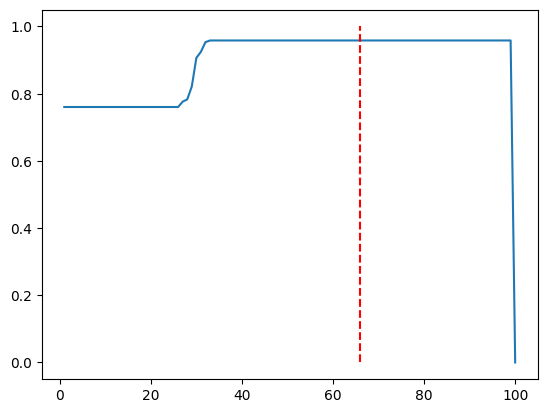

In [33]:
%%time
from sklearn.metrics import f1_score
def find_robust_threshold(mean_probs_per_patient):

    
    best_f1 = -1
    best_thr = -1
    tot_per_tr_f1_scores = []
    threshold_predictions = []
    
    for threshold in list(range(1,101)):

        """ Concatenate mean probs and labels into two nsubset x timepoints lists """
        f1_scores = []
        patient_predictions = []
        resampled_ys = []
        probs = []
        for patient_probs_tuple in mean_probs_per_patient:
            
            for timep, timep_res_y in patient_probs_tuple:
                
                # get mean columns predicted probabilities 
                probs += list(timep)
                
                # get the resampled ys
                resampled_ys += list(timep_res_y)

        #print('Log: Concatenation: Done!')
            
        y_pred = []
        y_pred = (np.array(probs) >= threshold*0.01).astype(int) #checks column by column if the element is > than the threshold and converts it in 1 or 0
        #print(f'Threshold: {threshold*0.01}. Preds: {y_pred}')

        # compute f1 score on the concatenated timepoints results 
        total_f1_score = f1_score(resampled_ys, y_pred, pos_label = 1, zero_division=1)
        #print(f'f1_score: {total_f1_score}\n')
        
        tot_per_tr_f1_scores.append(total_f1_score) # Visualization purposes
        
        if total_f1_score > best_f1:
                best_f1 = total_f1_score
                best_thr = threshold*0.01
        #print('')
    
    """ Best Threshold selection section """
    #find threshold
    max_f1 = max(tot_per_tr_f1_scores)
    best_thresholds_idx = []
    
    best_thresholds_idx = [i for i, f1 in enumerate(tot_per_tr_f1_scores) if f1 == max_f1]

    # whether multiple threholds provides the maximum f1_score, the median is taken
    best_threshold = np.median(best_thresholds_idx)
    print(best_threshold)
    plt.plot(list(range(1, 101)), tot_per_tr_f1_scores)
    plt.vlines(x=best_threshold + 1, ymin = 0, ymax = 1, color='red', linestyle='--')
    print(f'Chosen threshold: {best_threshold + 1}. Associated F1_score: {tot_per_tr_f1_scores[int(best_threshold)]}' )
    
    return best_threshold + 1, tot_per_tr_f1_scores

best_threshold = 0
best_threshold, tot_per_tr_f1_scores = find_robust_threshold(mean_probs_per_patient)

print(tot_per_tr_f1_scores)
#del per_donor_resampled_y

In [34]:
end = time.time() - start
print(f'{end/60} minutes')

1.3356942256291708 minutes


In [35]:
best_threshold

66.0

In [36]:

save_path = f'{fixed_path}CellCNN\\results\\old\\'
folder_name = f'model_{model_setting}'
model_save_path = f'{save_path}{folder_name}\\'
os.makedirs(model_save_path, exist_ok=True)

with open(f'{model_save_path}original_old_threshold.json', "w", encoding="utf-8") as f:
    json.dump(best_threshold, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_tuning_thr_f1_scores.json', "w", encoding="utf-8") as f:
    json.dump(tot_per_tr_f1_scores, f, default=default_serializer, ensure_ascii=False, indent=2)


# Test label prediction

In [37]:
import time
start = time.time()


In [38]:

def sub_resampling_list(k, nsub_per_sub = 50):
    remaining_k = k
    sub_division = []
    
    while remaining_k > 0:
        print(remaining_k)
        if remaining_k >= nsub_per_sub:
            sub_division.append(nsub_per_sub)
            remaining_k -= nsub_per_sub
            print(sub_division)
        else:
            sub_division.append(remaining_k)
            return sub_division
    return sub_division
            
sub_division = sub_resampling_list(k, nsub_per_sub = 50)
print(sub_division)

50
[50]
[50]


In [39]:
%%time

per_donor_original_test_datasets, per_donor_original_test_y = retrieve_labels(test_datasets_extracted, remove = False)

n = 100000
k = 100
seed = 42
def test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials):
    
    counter = 1
    per_donor_resampled_test_datasets =[]
    per_donor_resampled_test_y = []
    per_donor_perc = []
    
    test_total_labels = []
    test_total_pred_lists = []
    test_total_trial_pred_lists = []
    
    for patient in per_donor_original_test_datasets:
        per_dataset_resampled_datasets = []
        per_dataset_resampled_ys = []
        per_dataset_perc = []
        patient_timepoints_labels = []
        patient_pred_list = []
        patient_trial_pred_list = []
        
        for file in patient:
            sub_division = sub_resampling_list(k, nsub_per_sub = 50)
            print(sub_division)
            total_resampled_y = []
            total_positive_probs = [[] for _ in range(trials)]
            print(total_positive_probs)
            division_positive_probs_mean = []
            print(f'Prediction {counter}')
            counter += 1
            
            for _, division in enumerate(sub_division):
                print(division)
                resampled_datasets, resampled_y, blast_perc, seed = subset_sampling(dataset = file, ncells = n, nsubsets = division, seed = seed)
                
                # predict labels 
                new_datasets_predictions_list, new_datasets_results_list = trials_test_CellCNN_old(models_lists, resampled_datasets)
                positive_probs = []
                
                """ Extraction and mean probabilities section """
                for iterat, trial in enumerate(new_datasets_predictions_list):
                    positive_probs.append(pd.DataFrame(trial)[1].values) # appends the probability of positive classification
                    total_positive_probs[iterat] += list(pd.DataFrame(trial)[1].values)
        
                 #it converts the list of (list of) probabilities into an array of lists of prob
                
                # Computes the mean over the columns ( it takes the first element of all arrays and make the mean, then the second and so on)
                division_positive_probs_mean.append(np.mean(positive_probs , axis=0))
                
                total_resampled_y += resampled_y

            positive_probs_mean = np.concatenate(division_positive_probs_mean)
            #print(f'Len of Mean: {len(positive_probs_mean)}')
            #print(f'Len of probs: {len(total_positive_probs)}')
            """ Threshold prediction section """
            mean_timepoint_probs = np.mean(positive_probs_mean) # mean percentage of timepoints labelled as with blast cells
                
            if mean_timepoint_probs >= best_threshold*0.01:
                    patient_timepoints_labels.append(1)
            else:
                    patient_timepoints_labels.append(0)
            
            
            patient_pred_list.append(positive_probs_mean) # stores the mean subset probabilities
            patient_trial_pred_list.append(total_positive_probs) # stores all probabilities af all trials
            
            per_dataset_resampled_ys.append(total_resampled_y)
            
        test_total_labels.append(patient_timepoints_labels)
        test_total_pred_lists.append(patient_pred_list)
        
        test_total_trial_pred_lists.append(patient_trial_pred_list)
        per_donor_resampled_test_y.append(per_dataset_resampled_ys)
    
    return test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y
    
test_total_labels, test_total_pred_lists, test_total_trial_pred_lists, per_donor_resampled_test_y = test_res_pred(models_lists, per_donor_original_test_datasets, n, k, seed, best_threshold, trials) 
#[patient1,                                               ... , patient5]
#[[patient1_timepoint1_probs, patient1_timepoint2_probs], ... ,[patient5_timepoint1_probs, patient5_timepoint2_probs]]


150
[50]
100
[50, 50]
50
[50, 50, 50]
[50, 50, 50]
[[], [], [], [], [], [], [], [], [], []]
Prediction 1
50
10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 38ms/step
Done
Trial 1 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 104ms/step
Done
Trial 2 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

... (771 outputs left out)

C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 37ms/step
Done
Trial 9 Done!

10
Prediction started...


C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
C:\Anaconda37\envs\jupyter_env\lib\site-packages\sklearn\utils\validat

2/2 [==============================] - 0s 58ms/step
Done
Trial 10 Done!

CPU times: total: 32min 59s
Wall time: 16min 49s


In [40]:
print(test_total_labels)
#[[1, 1], [1, 1], [0], [1, 1, 0], [1, 0], [1, 1, 0]]

[[0, 1], [1, 0], [1], [1, 1, 0], [1, 0], [1, 1, 0]]


In [41]:
def flatten(nested):
    if nested is None:
        return []
    if not isinstance(nested, (list, tuple)):
        return [nested]
    result = []
    for item in nested:
        result.extend(flatten(item))
    return result
    
test_total_labels = test_total_labels
print(test_total_labels)

predicted_labels = flatten(test_total_labels)
true_labels = flatten(per_donor_original_test_y)
print(predicted_labels)
print(true_labels)

f1 = f1_score(predicted_labels, true_labels, pos_label = 1, zero_division=1)
print(f1)

[[0, 1], [1, 0], [1], [1, 1, 0], [1, 0], [1, 1, 0]]
[0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0]
[1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0]
0.8235294117647058


In [42]:

save_path = f'{fixed_path}CellCNN\\results\\old\\'
folder_name = f'model_{model_setting}'
model_save_path = f'{save_path}{folder_name}\\'
os.makedirs(model_save_path, exist_ok=True)

with open(f'{model_save_path}original_old_trials_pred_lists.json', "w", encoding="utf-8") as f:
    json.dump(test_total_trial_pred_lists, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_per_donor_resampled_test_y.json', "w", encoding="utf-8") as f:
    json.dump(per_donor_resampled_test_y, f, default=default_serializer, ensure_ascii=False, indent=2)

with open(f'{model_save_path}original_old_per_donor_resampled_test_y.json', "w", encoding="utf-8") as f:
    json.dump(per_donor_resampled_test_y, f, default=default_serializer, ensure_ascii=False, indent=2)


timepoints_blast_perc = []
for donor in per_donor_original_test_datasets:
    for i, dataset in enumerate(donor):
        blast_n = (dataset['IsBlast'] == 1).sum()/len(dataset)
        timepoints_blast_perc.append(round(blast_n*100,4))
        
with open(f'{model_save_path}original_old_timepoints_blast_perc.json', "w", encoding="utf-8") as f:
    json.dump(timepoints_blast_perc, f, default=default_serializer, ensure_ascii=False, indent=2)

Predicted  Labels: [[0, 1], [1, 0], [1], [1, 1, 0], [1, 0], [1, 1, 0]]
Timepoints Labels: [[1, 1], [1, 1], [0], [1, 1, 0], [1, 0], [1, 1, 0]]


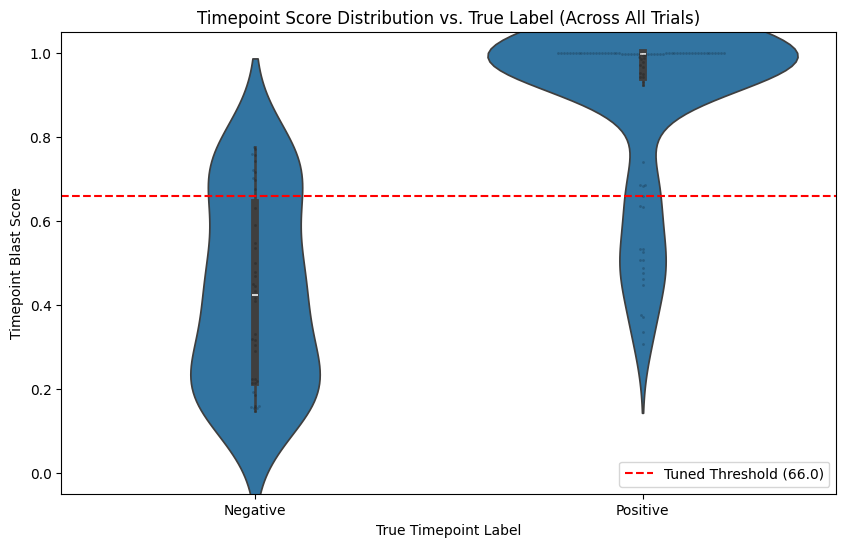

In [43]:
from sklearn.metrics import f1_score

def final_trials_prediction(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y, best_threshold):
    from sklearn.metrics import f1_score
    """ Elaborate data to show distribution of trial results over the entire set of timepoints and patiets"""
    prob_data = []
    f1_data = []
    boxplot_data = []
    
    for patient, patient_ys, patient_resampled_y in zip(total_trial_pred_lists, per_donor_original_test_y, per_donor_resampled_test_y):

        for timepoint, true_timepoint_y, true_resampled_y in zip(patient, patient_ys, patient_resampled_y):
            label_str = "Positive" if true_timepoint_y == 1 else "Negative"
            
            timepoint_boxplot_data = []
            timepoint_f1_data = []
            #print(timepoint)
            for trial in timepoint: # from each timepoint multiple samples has been generated. each sample has been predicted 10 times using the same 'best' model but using a different seed each time
                             # each sub is a pediction of the 20 samples of a single timepoint

                #print(trial)
                trial_prob = np.mean(trial) # mean of the probabilities of the subsets
                
                trial_pred = (np.array(trial) >= best_threshold*0.01).astype(int)
                #print(trial_pred)
                #print(true_resampled_y)
                
                trial_f1 =  f1_score(true_resampled_y, trial_pred, pos_label = 1, zero_division=1)
                #print(rqver)
                
                prob_data.append({
                "True_Label": label_str,
                "Timepoint_Score": trial_prob
                })
                
                
                timepoint_boxplot_data.append(trial_prob)
                timepoint_f1_data.append(trial_f1)
                
            boxplot_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_boxplot_data
                })
            
            f1_data.append({
                "True_Label": true_timepoint_y,
                "Timepoint_trials_scores": timepoint_f1_data
                })
                
    return prob_data, boxplot_data, f1_data
    
    
print(f'Predicted  Labels: {test_total_labels}')

print(f'Timepoints Labels: {per_donor_original_test_y}')

plot_data, boxplot_data, f1_data = final_trials_prediction(test_total_trial_pred_lists, 
                                                           per_donor_original_test_y, per_donor_resampled_test_y, best_threshold)
#print(plot_data)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert your data into a DataFrame
df = pd.DataFrame(plot_data)

# --- Create the plot ---
plt.figure(figsize=(10, 6))

# A Violin plot is like a boxplot but shows the full distribution
sns.violinplot(
    x="True_Label", 
    y="Timepoint_Score", 
    data=df,
    order=["Negative", "Positive"] # Ensure this order
)

# You can also add a swarmplot to see the individual points
sns.swarmplot(
    x="True_Label",
    y="Timepoint_Score",
    data=df,
    color="black",
    alpha=0.2, # Make points transparent
    size=2,
    order=["Negative", "Positive"]
)

# --- Add your threshold line! ---
# This is the line that separates your predictions
TUNED_THRESHOLD = best_threshold # The threshold you found in your tuning
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')
plt.ylim(-0.05, 1.05) # (Set the y-axis limit, 1.05 gives a little space)
plt.title('Timepoint Score Distribution vs. True Label (Across All Trials)')
plt.ylabel('Timepoint Blast Score')
plt.xlabel('True Timepoint Label')
plt.legend()
plt.show()


C:\Users\Enrico Didoli\AppData\Local\Temp\ipykernel_8684\2472743216.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax1.boxplot(timepoints_trials_scores, labels=timepoints_labels)


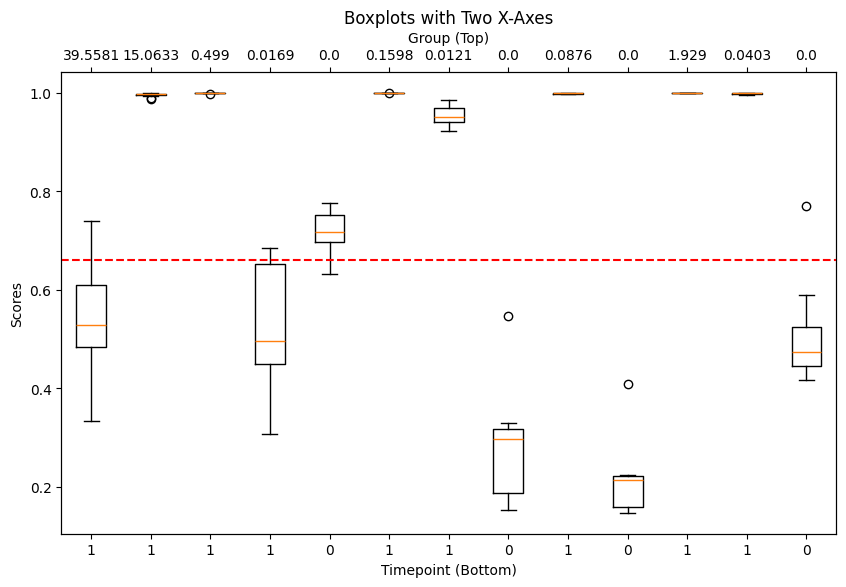

In [44]:
#print(boxplot_data)

timepoints_labels = [timepoint["True_Label"] for i, timepoint in enumerate(boxplot_data)]
timepoints_trials_scores = [timepoint["Timepoint_trials_scores"] for timepoint in boxplot_data]
#print(timepoints_labels)
#print(timepoints_trials_scores)

# --- Your Solution (One Line) ---
# Create a figure and axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# 2. Plot the boxplot on the first axes (ax1)
ax1.boxplot(timepoints_trials_scores, labels=timepoints_labels)
ax1.set_xlabel("Timepoint (Bottom)")
ax1.set_ylabel("Scores")

# 3. Create the SECOND axes (ax2)
ax2 = ax1.twiny()

# 4. Configure the second axes
# Make ax2 have the same limits and ticks as ax1
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]

# Set the new labels for the top axis
ax2.set_xticklabels(timepoints_blast_perc)
ax2.set_xlabel("Group (Top)")
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')

plt.title("Boxplots with Two X-Axes")
plt.show()

C:\Users\Enrico Didoli\AppData\Local\Temp\ipykernel_8684\53204109.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax1.boxplot(f1_timepoints_trials_scores, labels=timepoints_labels)


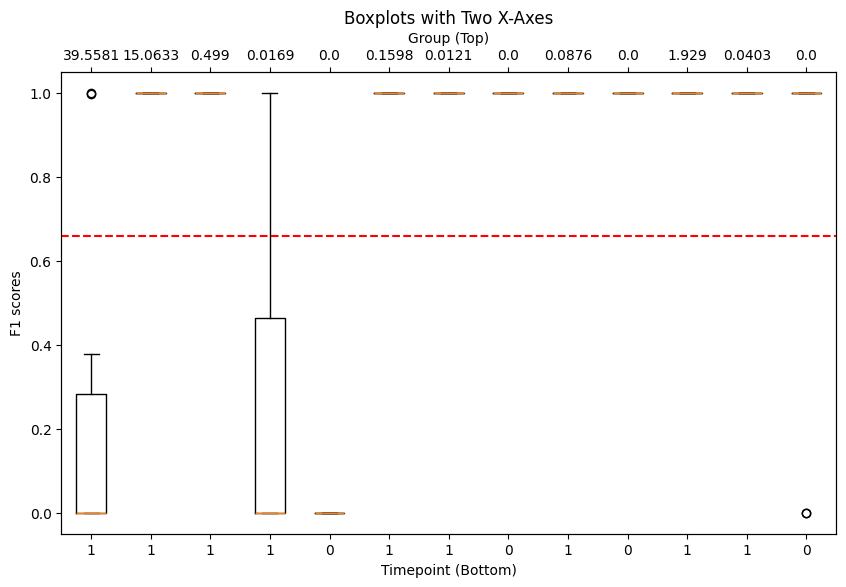

In [45]:
#print(boxplot_data)

timepoints_labels = [timepoint["True_Label"] for i, timepoint in enumerate(f1_data)]
f1_timepoints_trials_scores = [timepoint["Timepoint_trials_scores"] for timepoint in f1_data]
#print(timepoints_labels)
#print(timepoints_trials_scores)

# --- Your Solution (One Line) ---
# Create a figure and axes
fig, ax1 = plt.subplots(figsize=(10, 6))

# 2. Plot the boxplot on the first axes (ax1)
ax1.boxplot(f1_timepoints_trials_scores, labels=timepoints_labels)
ax1.set_xlabel("Timepoint (Bottom)")
ax1.set_ylabel("F1 scores")

# 3. Create the SECOND axes (ax2)
ax2 = ax1.twiny()

# 4. Configure the second axes
# Make ax2 have the same limits and ticks as ax1
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(ax1.get_xticks()) # Positions [1, 2, 3, 4]

# Set the new labels for the top axis
ax2.set_xticklabels(timepoints_blast_perc)
ax2.set_xlabel("Group (Top)")
plt.axhline(y=TUNED_THRESHOLD*0.01, color='red', linestyle='--', label=f'Tuned Threshold ({TUNED_THRESHOLD})')

plt.title("Boxplots with Two X-Axes")
plt.show()

In [46]:
end = time.time() - start
print(f'{end/60} minutes')

16.885403819878896 minutes


In [47]:
%whos

Variable                            Type             Data/Info
--------------------------------------------------------------
CellCnn                             type             <class 'old_cellCnn.model_grid.CellCnn'>
TSNE                                type             <class 'sklearn.manifold._t_sne.TSNE'>
TUNED_THRESHOLD                     float64          66.0
ax1                                 Axes             Axes(0.125,0.11;0.775x0.77)
ax2                                 Axes             Axes(0.125,0.11;0.775x0.77)
best_nsub                           int              780
best_threshold                      float64          66.0
blast_donors                        list             n=5
blast_n                             float64          0.0
blast_perc                          list             n=3
boxplot_data                        list             n=13
cellcnn_path                        str              C:\Users\Enrico Didoli\0.Master_Thesis\CellCNN/
cells_per_sub          

In [48]:
import platform

print(platform.system())
print(platform.platform())

Windows
Windows-10-10.0.19042-SP0
